# Unit 3, Exercise 1: covariance and Pearson correlation

The first code cell is the module's notebook, unchanged. Everything under **My changes** is mine.
The task was to change the data and watch what happens to covariance and correlation.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

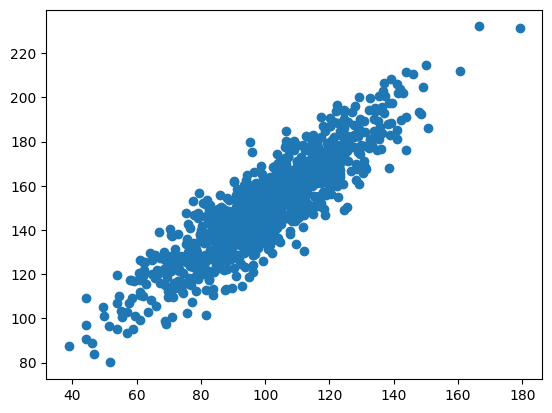

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


In [1]:

# calculate the Pearson's correlation between two variables
from numpy import mean                              # average of a list of numbers
from numpy import std                               # standard deviation: how spread out the numbers are
from numpy import cov                               # covariance: whether two variables move together
from numpy.random import randn                      # random numbers from a normal (bell curve) distribution
from numpy.random import seed                       # fixes the random numbers so every run is the same
from matplotlib import pyplot as plt                # plotting
import seaborn as sns                               # nicer statistical plots

from scipy.stats import pearsonr                    # Pearson correlation coefficient and its p-value
# seed random number generator
seed(1)                                             # same random numbers every run

# prepare data
data1 = 20 * randn(1000) + 100                      # 1,000 values centred on 100 with a spread of 20
data2 = data1 + (10 * randn(1000) + 50)             # data1 plus noise, so data2 rises with data1

# calculate covariance matrix
covariance = cov(data1, data2)                      # 2 x 2 covariance matrix of the two variables

# calculate Pearson's correlation
corr, _ = pearsonr(data1, data2)                    # Pearson r; the p-value is thrown away with _

# plot
plt.scatter(data1, data2)                           # one dot per pair of values
plt.show()                                          # draw the plot

# summarize
print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))  # average and spread of data1
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))  # average and spread of data2
print('Covariance: %.3f' % covariance[0][1])        # top-right of the matrix is the covariance between the two
print('Pearsons correlation: %.3f' % corr)          # r runs from -1 to 1; close to 1 means a strong positive link


## My changes

### 1. More noise, weaker correlation

In [2]:
import numpy as np                                   # numpy: random numbers and arrays
from scipy.stats import pearsonr                     # Pearson correlation coefficient

rng = np.random.default_rng(1)                       # random number generator with a fixed seed, so results repeat
base = 20 * rng.standard_normal(1000) + 100          # 1,000 values centred on 100 with a spread of 20 (like the module's data1)
print(f"{'noise sd':>8} | {'covariance':>10} | {'pearson r':>9}")   # table header
for noise_sd in [0, 5, 10, 20, 50, 100]:             # try six levels of noise, from none to huge
    other = base + (noise_sd * rng.standard_normal(1000) + 50)   # second variable = first + 50 + random noise
    cov = np.cov(base, other)[0][1]                  # covariance: the off-diagonal value of the 2x2 covariance matrix
    r, _ = pearsonr(base, other)                     # correlation (the p-value is ignored here)
    print(f"{noise_sd:>8} | {cov:>10.1f} | {r:>9.3f}")   # one table row per noise level

noise sd | covariance | pearson r
       0 |      389.5 |     1.000
       5 |      386.6 |     0.971
      10 |      392.9 |     0.889
      20 |      390.6 |     0.707
      50 |      318.7 |     0.309
     100 |      453.7 |     0.232


### 2. Same relationship, different units

In [3]:
# Multiply the second variable by 100, like switching metres to centimetres.
other = base + (10 * rng.standard_normal(1000) + 50)                 # a fresh second variable with moderate noise
for label, y in [("original units", other), ("x100 units", other * 100)]:   # the same data in two different units
    # covariance changes with the units, correlation should not
    print(f"{label:<15} covariance={np.cov(base, y)[0][1]:>10.1f}  pearson r={pearsonr(base, y)[0]:.3f}")  # covariance changes with the units, correlation should not

original units  covariance=     391.4  pearson r=0.890
x100 units      covariance=   39140.3  pearson r=0.890


### 3. Shapes that Pearson misreads

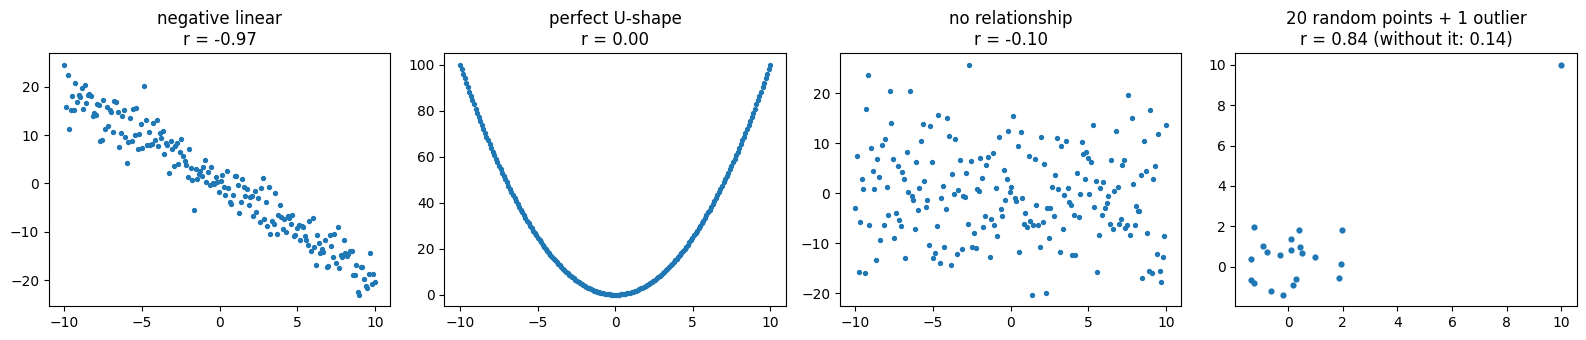

negative linear  r = -0.97
perfect U-shape  r = 0.00
no relationship  r = -0.10
outlier case     r = 0.84  (without the outlier: 0.14)


In [4]:
import matplotlib.pyplot as plt                      # plotting

x = np.linspace(-10, 10, 200)                        # 200 evenly spaced x values from -10 to 10
cases = {                                            # three different kinds of relationship with x
    "negative linear": -2 * x + rng.normal(0, 3, x.size),   # a straight downward line plus some noise
    "perfect U-shape": x ** 2,                       # y is exactly x squared: perfectly related, but not a straight line
    "no relationship": rng.normal(0, 10, x.size),   # pure noise that ignores x
}
# One outlier added to an otherwise unrelated small sample
xs = rng.normal(0, 1, 20); ys = rng.normal(0, 1, 20)          # 20 random points with no relationship
xs_out, ys_out = np.append(xs, 10), np.append(ys, 10)         # the same 20 points plus one far-out point at (10, 10)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))   # four plots side by side
for ax, (title, y) in zip(axes, cases.items()):     # the first three plots, one per case
    ax.scatter(x, y, s=8); ax.set_title(f"{title}\nr = {pearsonr(x, y)[0]:.2f}")   # scatter with r in the title
axes[3].scatter(xs_out, ys_out, s=12)               # fourth plot: the outlier example
axes[3].set_title(f"20 random points + 1 outlier\nr = {pearsonr(xs_out, ys_out)[0]:.2f} "  # r with and without the outlier
                  f"(without it: {pearsonr(xs, ys)[0]:.2f})")       # r with and without the outlier
plt.tight_layout(); plt.show()                       # tidy the spacing and draw
for title, y in cases.items():                       # print the same r values as text, so they can be quoted
    print(f"{title:<16} r = {pearsonr(x, y)[0]:.2f}")  # one line per case
print(f"outlier case     r = {pearsonr(xs_out, ys_out)[0]:.2f}  (without the outlier: {pearsonr(xs, ys)[0]:.2f})")  # the outlier case, with and without the extra point

## What I took from it


- **Covariance and correlation answer different questions.** As I added noise, the correlation fell from
  1.00 to 0.23. The covariance barely moved, staying around 390 until the noise got huge. Covariance
  measures how much the two variables move together *in their own units*. The noise I added is
  independent, so it doesn't add to that shared movement. Correlation divides by the spread of each
  variable, so it falls as the noise grows. That's why correlation is the one you can read.
- **Covariance depends on units, correlation doesn't.** Multiplying one variable by 100 multiplied the
  covariance by 100 (391 to 39,140). The correlation stayed at 0.890. Same relationship, different number.
  You can't compare covariances across datasets measured in different units.
- **Pearson only sees straight lines.** The U-shape is a perfect relationship, y is exactly x², and Pearson
  scores it 0.00. A zero correlation does not mean "no relationship". It means "no straight-line
  relationship".
- **One point can invent a correlation.** Twenty random points gave r = 0.14. Adding one extreme point took it
  to 0.84. Always plot the data before trusting r.